In [1]:
!nvidia-smi

Tue Jun  2 02:40:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

###Installing required python packages

In [2]:
!pip install -q datasets evaluate bert_score rouge_score torch torchvision transformers peft gdown --upgrade pip --upgrade torchao

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 529.0/529.0 kB 24.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 532.3/532.3 MB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.2/366.2 MB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.0/206.0 MB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 201.5/201.5 MB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 78.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 MB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 87.1 MB/s eta 0:00:00
   ━━━━━━

#Dataset

Huggingface Link: https://huggingface.co/datasets/flaviagiammarino/path-vqa

The PathVQA Dataset is available on Hugging Face and contains 19,654 training, 6,259 validation, and 6,719 test question-answer pairs across approximately 5,004 pathology images.

The PathVQA Dataset is a large-scale medical visual question answering benchmark designed for pathology image understanding. It contains more than 32,000 question-answer pairs associated with pathology images collected from publicly available medical sources. The dataset supports multimodal AI research by combining visual pathology information with natural language reasoning tasks, enabling models to answer clinically relevant questions about tissue appearance, disease characteristics, and diagnostic findings. PathVQA has become a widely used benchmark for evaluating medical VQA systems and multimodal large language models in digital pathology research.

[1] He, Xuehai, et al. "Towards visual question answering on pathology images." Proceedings of the 59th Annual Meeting of the Association for Computational Linguistics and the 11th International Joint Conference on Natural Language Processing (Volume 2: Short Papers). 2021.

[2] He, Xuehai, et al. "Pathvqa: 30000+ questions for medical visual question answering." arXiv preprint arXiv:2003.10286 (2020).

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


data/validation-00000-of-00003-90a5518d2(…):   0%|          | 0.00/41.3M [00:00<?, ?B/s]

data/validation-00001-of-00003-cbfe947a3(…):   0%|          | 0.00/45.7M [00:00<?, ?B/s]

data/validation-00002-of-00003-9ec816895(…):   0%|          | 0.00/64.7M [00:00<?, ?B/s]

Generating validation split: 0 examples [00:00, ? examples/s]

sample size: 6259
keys: dict_keys(['image', 'question', 'answer'])
QA word-length: min=3, mean=7.9, max=38


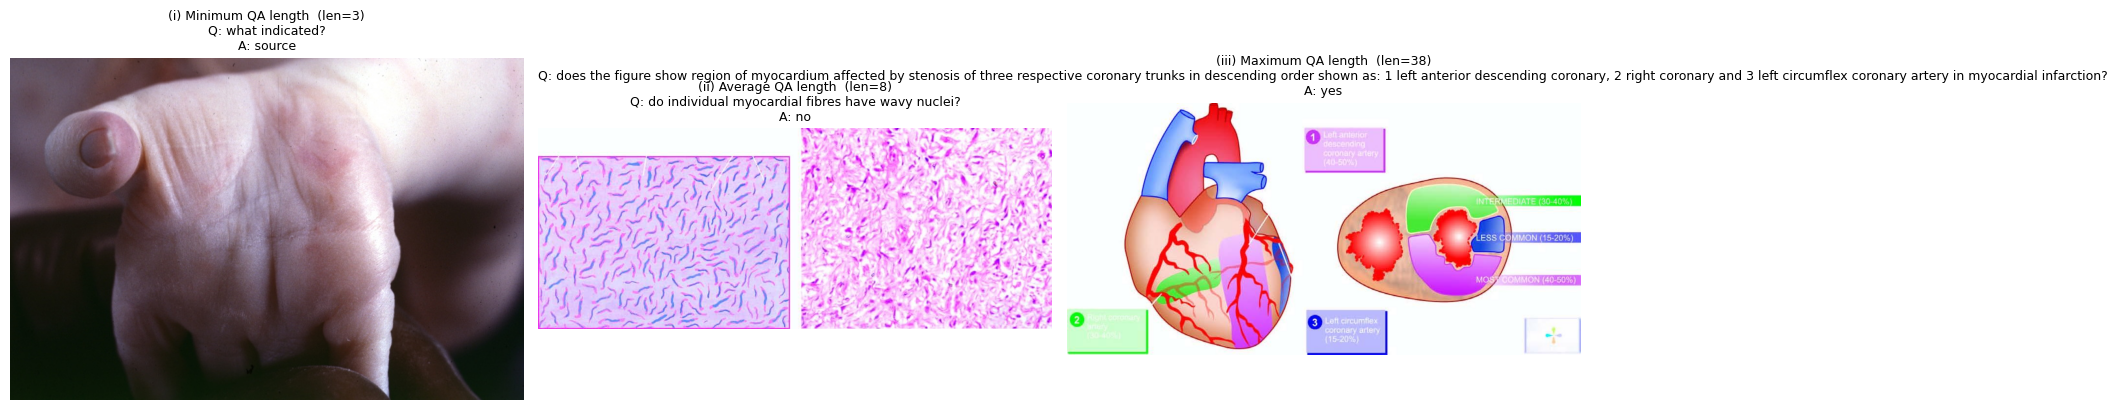

In [3]:
from datasets import load_dataset
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

pathvqa_valid = load_dataset("parquet", data_files={"validation": "hf://datasets/flaviagiammarino/path-vqa/data/validation-*.parquet"}, split="validation")
print('sample size:', len(pathvqa_valid))
print('keys:', pathvqa_valid[0].keys())

# === Task 1: visualise 3 samples by QA length (min / average / max) ========
# QA length = number of words in the question + answer.
questions = pathvqa_valid["question"]
answers = pathvqa_valid["answer"]
qa_lengths = np.array([len((q + " " + a).split()) for q, a in zip(questions, answers)])

min_idx = int(np.argmin(qa_lengths))                              # shortest QA
max_idx = int(np.argmax(qa_lengths))                              # longest QA
avg_idx = int(np.argmin(np.abs(qa_lengths - qa_lengths.mean())))  # closest to mean

print(f"QA word-length: min={qa_lengths.min()}, mean={qa_lengths.mean():.1f}, max={qa_lengths.max()}")

samples = [
    ("(i) Minimum QA length", min_idx),
    ("(ii) Average QA length", avg_idx),
    ("(iii) Maximum QA length", max_idx),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, (label, idx) in zip(axes, samples):
    s = pathvqa_valid[idx]
    ax.imshow(s["image"])
    ax.axis('off')
    ax.set_title(f"{label}  (len={qa_lengths[idx]})\nQ: {s['question']}\nA: {s['answer']}",
                 fontsize=9)
plt.tight_layout()
plt.show()


#Prepare Dataloader

split: train = 2400 and test=600
Sample size: Training: 2400 validation: 600
image resolution: torch.Size([3, 224, 224])


Text(0.5, 1.0, 'Q: is gross islands of tumor?\nA: yes')

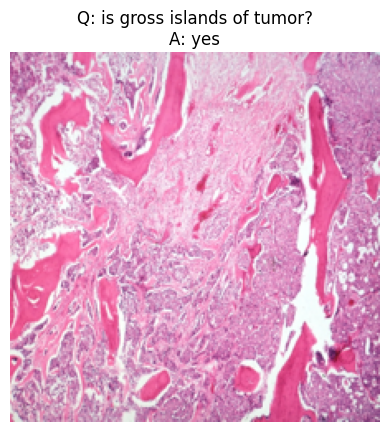

In [4]:
import torch
from torch.utils.data import Dataset
from PIL import Image
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from torch.utils.data import DataLoader


class PathVQADataset(Dataset):
    def __init__(self, hf_dataset):
        """
        hf_dataset: HuggingFace dataset (already loaded split)
        """

        self.dataset = hf_dataset

        self.transform = transforms.Compose([
            transforms.Resize((224, 224), interpolation=InterpolationMode.BICUBIC),
            transforms.ToTensor(),
        ])

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        sample = self.dataset[idx]

        # --- Image ---
        # HF dataset already provides PIL image
        raw_image = sample["image"].convert('RGB')
        img = self.transform(raw_image)

        # --- Question & Answer ---
        question = sample["question"]
        answer = sample["answer"]

        return img, question, answer

subset = pathvqa_valid.shuffle(seed=42).select(range(3000))
split_dataset = subset.train_test_split(test_size=0.2, seed=42)

# split_dataset = pathvqa_valid.train_test_split(test_size=0.2, seed=42)

train_data = split_dataset["train"]
val_data   = split_dataset["test"]
print(f'split: train = {len(train_data)} and test={len(val_data)}')

train_dataset = PathVQADataset(train_data)
val_dataset   = PathVQADataset(val_data)
print('Sample size: Training:', len(train_dataset), 'validation:', len(val_dataset))

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=32, shuffle=False)


img, question, answer = train_dataset[1]
print('image resolution:', img.size())
plt.axis('OFF')
plt.imshow(img.permute(1,2,0))
plt.title(f'Q: {question}\nA: {answer}', fontsize=12)

#Model Architecture

Paper: https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf

GPT-2 uses a decoder-only transformer architecture with multiple model sizes; the commonly used GPT-2 Base model contains 12 transformer blocks (layers), a context window of 1024 tokens, a hidden embedding size of 768, and about 117 million parameters, while larger variants scale up to 48 transformer blocks and 1.5 billion parameters.

[1] Radford, A., Wu, J., Child, R., Luan, D., Amodei, D., & Sutskever, I. (2019). Language models are unsupervised multitask learners. OpenAI blog, 1(8), 9.

###Cross-Attention Fusion

In [5]:
import math
import torch
import torch.nn as nn
from transformers import GPT2Tokenizer, GPT2LMHeadModel
from transformers import ViTModel, BlipTextModel
from peft import get_peft_model

####Cross-Attention Fusion###########
class CrossAttentionFusion(nn.Module):
    def __init__(self, hidden_dim=768, num_heads=8, dropout=0.1):
        super().__init__()

        self.cross_attn = nn.MultiheadAttention(
            embed_dim=hidden_dim,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True
        )

        self.norm1 = nn.LayerNorm(hidden_dim)
        self.norm2 = nn.LayerNorm(hidden_dim)

        self.ffn = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim * 4),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim * 4, hidden_dim),
            nn.Dropout(dropout)
        )

    def forward(self, text_embeds, image_embeds, text_att_mask=None):
        """
        text_embeds:  [B, T, 768]
        image_embeds: [B, N, 768]
        text attends to image
        """

        attended_text, attn_weights = self.cross_attn(
            query=text_embeds,
            key=image_embeds,
            value=image_embeds,
            need_weights=False
        )

        x = self.norm1(text_embeds + attended_text)
        x = self.norm2(x + self.ffn(x))

        return x

W0602 02:44:21.861000 1180 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W0602 02:44:21.930000 1180 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


###Gated Cross-Attention Fusion

In [6]:
import torch
import torch.nn as nn


class GatedCrossAttentionFusion(nn.Module):
    """Gated cross-attention fusion (Flamingo-style tanh gating).

    Text tokens attend to the image tokens, and a learnable gate controls how
    much of the attended visual information is injected into the text stream.
    The gates are initialised to 0 so that tanh(0)=0 and the module starts as an
    identity mapping; the network then learns the right fusion strength during
    training, which stabilises adaptation of the frozen GPT-2 / ViT backbones.
    """

    def __init__(self, hidden_dim=768, num_heads=8, dropout=0.1):
        super().__init__()

        self.cross_attn = nn.MultiheadAttention(
            embed_dim=hidden_dim,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True
        )

        self.norm1 = nn.LayerNorm(hidden_dim)
        self.norm2 = nn.LayerNorm(hidden_dim)

        self.ffn = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim * 4),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim * 4, hidden_dim),
            nn.Dropout(dropout)
        )

        # Learnable scalar gates, initialised at 0 -> tanh(0) = 0 (identity start)
        self.attn_gate = nn.Parameter(torch.zeros(1))
        self.ffn_gate = nn.Parameter(torch.zeros(1))

    def forward(self, text_embeds, image_embeds, text_att_mask=None):
        """
        text_embeds:  [B, T, 768]
        image_embeds: [B, N, 768]
        text attends to image, modulated by a learnable gate
        """

        attended_text, attn_weights = self.cross_attn(
            query=text_embeds,
            key=image_embeds,
            value=image_embeds,
            need_weights=False
        )

        # Gated residual connections: how much image/FFN signal to add is learned
        x = self.norm1(text_embeds + torch.tanh(self.attn_gate) * attended_text)
        x = self.norm2(x + torch.tanh(self.ffn_gate) * self.ffn(x))

        return x

###MedVQA model (Mulitmodal GPT2)

In [7]:
import math
import torch
import torch.nn as nn
from transformers import GPT2Tokenizer, GPT2LMHeadModel
from transformers import ViTModel, BlipTextModel
from peft import get_peft_model

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


class MedVQA(nn.Module):
    def __init__(self, peft_config=None, fusion_type="gated"):
        super(MedVQA, self).__init__()

        # visual encoder
        model_name = "google/vit-base-patch16-224-in21k"
        self.visual_encoder = ViTModel.from_pretrained(model_name)

        # Freeze all parameters in visual encoder
        for param in self.visual_encoder.parameters():
            param.requires_grad = False

        # tokenizer
        self.tokenizer = GPT2Tokenizer.from_pretrained('gpt2')
        self.tokenizer.pad_token = self.tokenizer.eos_token  # end of string

        # gpt2 decoder
        gpt = GPT2LMHeadModel.from_pretrained('gpt2')
        self.gpt = get_peft_model(gpt, peft_config)
        # self.gpt.print_trainable_parameters()  # Verify trainable LoRA parameters

        # Multimodal fusion: choose between plain and gated cross-attention
        if fusion_type == "gated":
            self.fusion = GatedCrossAttentionFusion(hidden_dim=768, num_heads=4)
        else:
            self.fusion = CrossAttentionFusion(hidden_dim=768, num_heads=4)

    def forward(self, image, qa_inputs_ids, qa_att_mask):
        image_embeds = self.visual_encoder(image).last_hidden_state
        # [B, 197, 768]

        text_embeds = self.gpt.get_input_embeddings()(qa_inputs_ids)
        # [B, T, 768]

        fused_embeds = self.fusion(
            text_embeds=text_embeds,
            image_embeds=image_embeds,
            text_att_mask=qa_att_mask
        )
        # [B, T, 768]

        gpt_output = self.gpt(
            inputs_embeds=fused_embeds,
            attention_mask=qa_att_mask
        )
        return gpt_output.logits

#Model Training

In [8]:
#Training Script for Multimodal GPT2 with LoRA
import os
import random
import argparse
import numpy as np

import torch
from torch import nn
from torch.utils.data import DataLoader
from transformers import GPT2Tokenizer
from peft import TaskType, LoraConfig

import warnings
warnings.filterwarnings('ignore')


def adjust_learning_rate(optimizer, shrink_factor):
    print("\nDECAYING learning rate.")
    for param_group in optimizer.param_groups:
        param_group['lr'] = param_group['lr'] * shrink_factor
    print("The new learning rate is %f\n" % (optimizer.param_groups[0]['lr'],))


def train(args, train_dataloader, model, criterion, optimizer, epoch, tokenizer, device):
    model.train()
    total_loss = []

    for i, (images, questions, answers) in enumerate(train_dataloader, 0):
        # Build "Question: ... \nAnswer: ..." prompts and tokenize them
        qa_prompt = [f'Question: {q}\nAnswer: {a}' for q, a in zip(questions, answers)]
        qa_prompt_inputs = tokenizer(
            qa_prompt, truncation=True, padding="max_length",
            max_length=int(args.seq_length), return_tensors="pt"
        )

        labels = qa_prompt_inputs['input_ids'].clone().to(device)

        # Mask the question tokens and the padding so loss is only on the answer
        for idx, q in enumerate(questions):
            q_prompt = f"Question: {q}\nAnswer: "
            q_length = len(tokenizer(q_prompt)["input_ids"]) - 1

            labels[idx, :q_length] = -100  # mask question
            eos_mask = (labels[idx] == tokenizer.eos_token_id)
            if eos_mask.sum() > 1:  # keep a single EOS, mask the rest (padding)
                first_eos_pos = eos_mask.nonzero()[0].item()
                labels[idx, (first_eos_pos + 1):] = -100

        logits = model(
            image=images.to(device),
            qa_inputs_ids=qa_prompt_inputs['input_ids'].to(device),
            qa_att_mask=qa_prompt_inputs['attention_mask'].to(device)
        )

        # Shift for next-token prediction
        shift_logits = logits[:, :-1, :].contiguous()
        shift_labels = labels[:, 1:].contiguous()

        shift_logits = shift_logits.view(-1, shift_logits.size(-1))
        shift_labels = shift_labels.view(-1)
        loss = criterion(shift_logits, shift_labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss.append(loss.item())
        if i % 50 == 0:
            print("Training - Epoch: {}/{}, Iteration: {}/{}, Training Loss: {:.6f}".format(
                epoch, args.epochs, i, len(train_dataloader), np.array(total_loss).mean()))


def validate(args, val_loader, model, criterion, epoch, tokenizer, device):
    total_loss = []
    model.eval()
    with torch.no_grad():
        for i, (images, questions, answers) in enumerate(val_loader, 0):
            qa_prompt = [f'Question: {q}\nAnswer: {a}' for q, a in zip(questions, answers)]
            qa_prompt_inputs = tokenizer(
                qa_prompt, truncation=True, padding="max_length",
                max_length=int(args.seq_length), return_tensors="pt"
            )

            labels = qa_prompt_inputs['input_ids'].clone().to(device)

            for idx, q in enumerate(questions):
                q_prompt = f"Question: {q}\nAnswer: "
                q_length = len(tokenizer(q_prompt)["input_ids"]) - 1

                labels[idx, :q_length] = -100
                eos_mask = (labels[idx] == tokenizer.eos_token_id)
                if eos_mask.sum() > 1:
                    first_eos_pos = eos_mask.nonzero()[0].item()
                    labels[idx, (first_eos_pos + 1):] = -100

            logits = model(
                image=images.to(device),
                qa_inputs_ids=qa_prompt_inputs['input_ids'].to(device),
                qa_att_mask=qa_prompt_inputs['attention_mask'].to(device)
            )

            shift_logits = logits[:, :-1, :].contiguous()
            shift_labels = labels[:, 1:].contiguous()

            shift_logits = shift_logits.view(-1, shift_logits.size(-1))
            shift_labels = shift_labels.view(-1)
            loss = criterion(shift_logits, shift_labels)
            total_loss.append(loss.item())

    return np.array(total_loss).mean()


def seed_everything(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    np.random.seed(seed)
    random.seed(seed)


def get_arg():
    parser = argparse.ArgumentParser(description='VisualQuestionAnswerGeneration')
    parser.add_argument('--epochs',         type=int,   default=3,      help='number of epochs to train for')
    parser.add_argument('--batch_size',     type=int,   default=32,     help='batch size')
    parser.add_argument('--workers',        type=int,   default=8,      help='for data-loading')
    parser.add_argument('--random_seed',    type=int,   default=42,     help='random seed')
    parser.add_argument('--seq_length',     type=int,   default=68,     help='sequence length for question and answer')
    parser.add_argument('--dropout',        type=float, default=0.1,    help='dropout')
    parser.add_argument('--lr',             type=float, default=0.0002, help='learning rate')
    parser.add_argument('--fusion_type',    default='gated',            help='gated / cross')
    parser.add_argument('--checkpoint_dir', default='checkpoints/',     help='path to checkpoint')
    args = parser.parse_args([])
    return args


class _Args:
    """Lightweight holder so the train()/validate() helpers above can be reused."""
    pass


def train_model(fusion_type="cross", lr=2e-4, epochs=3, batch_size=32,
                seq_length=68, dropout=0.1, seed=42,
                ckpt_path="checkpoints/cross.pth"):
    """Train a MedVQA model with the given fusion type and hyper-parameters,
    saving the best (lowest val-loss) checkpoint to `ckpt_path`.

    Returns (ckpt_path, best_val_loss). This single function is reused for every
    experiment row in Table 1 / Fig. 1 (Cross-Attention, Gated, and tuned)."""
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    args = _Args()
    args.epochs = epochs
    args.seq_length = seq_length
    args.lr = lr

    os.makedirs(os.path.dirname(ckpt_path) or ".", exist_ok=True)

    # train_data / val_data and PathVQADataset come from the dataloader section
    train_dataset = PathVQADataset(train_data)
    val_dataset   = PathVQADataset(val_data)
    train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_dataloader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    print(f'[{fusion_type}] train={len(train_dataset)} val={len(val_dataset)} '
          f'| lr={lr} epochs={epochs} batch={batch_size}')

    tokenizer = GPT2Tokenizer.from_pretrained('gpt2')
    tokenizer.pad_token = tokenizer.eos_token

    # LoRA: adapt only the attention projections of GPT-2
    lora_config = LoraConfig(
        task_type=TaskType.CAUSAL_LM, r=8, lora_alpha=16,
        lora_dropout=dropout, target_modules=["c_attn", "c_proj"]
    )

    model = MedVQA(peft_config=lora_config, fusion_type=fusion_type).to(device)
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'Trainable params: {trainable_params:,} / {total_params:,} '
          f'({100.0 * trainable_params / total_params:.2f}%)')

    optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    criterion = nn.CrossEntropyLoss(ignore_index=-100).to(device)

    best_val_loss = float('inf')
    print(f'[{fusion_type}] Start training.')
    for epoch in range(1, epochs + 1):
        train(args, train_dataloader=train_dataloader, model=model, criterion=criterion,
              optimizer=optimizer, epoch=epoch, tokenizer=tokenizer, device=device)
        val_loss = validate(args, val_loader=val_dataloader, model=model, criterion=criterion,
                            epoch=epoch, tokenizer=tokenizer, device=device)
        print(f'[{fusion_type}] Epoch {epoch}: validation loss = {val_loss:.6f}')
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), ckpt_path)
            tokenizer.save_pretrained(os.path.dirname(ckpt_path) or ".")
            print(f'[{fusion_type}] Best so far -> saved to {ckpt_path}')
    print(f'[{fusion_type}] End training. Best val loss = {best_val_loss:.6f}')

    # free GPU memory between experiments
    del model
    torch.cuda.empty_cache()
    return ckpt_path, best_val_loss

#Inference: few samples (prediction visualisations)

In [9]:
#run inference to collect the prediction visualisations
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from transformers import GPT2Tokenizer
from peft import TaskType, LoraConfig

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def greedy_search_single(image, question, model, tokenizer, max_length, device):
    """Greedy autoregressive decoding for a single (image, question) pair."""
    model.eval()
    with torch.no_grad():
        prompt_text = f"Question: {question}\nAnswer:"
        inputs = tokenizer(prompt_text, return_tensors="pt", add_special_tokens=False)
        input_ids = inputs['input_ids'].to(device)
        attention_mask = inputs['attention_mask'].to(device)

        # Pre-allocate a padded buffer we fill token-by-token
        padded_input_ids = torch.zeros((1, max_length), dtype=torch.long, device=device)
        padded_attention_mask = torch.zeros((1, max_length), dtype=torch.long, device=device)
        seq_len = input_ids.size(1)
        padded_input_ids[:, :seq_len] = input_ids
        padded_attention_mask[:, :seq_len] = attention_mask

        valid_length = seq_len
        generated_ids = []

        image = image.unsqueeze(0).to(device)  # add batch dim

        for _ in range(max_length - seq_len):
            logits = model(
                image=image,
                qa_inputs_ids=padded_input_ids[:, :valid_length],
                qa_att_mask=padded_attention_mask[:, :valid_length]
            )

            last_logits = logits[0, valid_length - 1]  # [vocab_size]
            next_token_id = torch.argmax(F.softmax(last_logits, dim=-1), dim=-1)

            if next_token_id.item() == tokenizer.eos_token_id:
                break

            padded_input_ids[0, valid_length] = next_token_id
            padded_attention_mask[0, valid_length] = 1
            valid_length += 1
            generated_ids.append(next_token_id.item())

        answer = tokenizer.decode(generated_ids, skip_special_tokens=True).strip()
        return answer


def inference_few_samples(sample_indices=[2, 80, 7], fusion_type="gated"):
    lora_config = LoraConfig(
        task_type=TaskType.CAUSAL_LM,
        r=8,
        lora_alpha=16,
        lora_dropout=0.1,
        target_modules=["c_attn", "c_proj"]
    )

    model = MedVQA(peft_config=lora_config, fusion_type=fusion_type)
    save_dir = 'checkpoints/best_model_ca.pth'
    model.load_state_dict(torch.load(save_dir, map_location=device))
    model.to(device)
    model.eval()

    tokenizer = GPT2Tokenizer.from_pretrained('gpt2')
    tokenizer.pad_token = tokenizer.eos_token

    val_dataset = PathVQADataset(val_data)
    print('Sample size: valid:', len(val_dataset))

    fig, axes = plt.subplots(1, len(sample_indices), figsize=(12, 5))
    for ax, idx in zip(axes, sample_indices):
        img, question, answer_gt = val_dataset[idx]

        pred_answer = greedy_search_single(img, question, model, tokenizer, max_length=34, device=device)
        img = img.permute(1, 2, 0)  # [C, H, W] -> [H, W, C] for imshow
        ax.imshow(img)
        ax.set_title(f'Q: {question}\nA: {answer_gt}\nPred: {pred_answer}', fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

# NOTE: `greedy_search_single` is reused by the experiment section below to
# build Fig. 1. The single-model demo `inference_few_samples()` is left as a
# helper; the consolidated Fig. 1 (one row per fusion method) is produced later.

#Inference: (Evaluation Metrics)

In [10]:
#run inference to collect the evaluation metrics (BLEU, ROUGE-L, and METEOR)
import os
import random
import numpy as np
import torch
from torch.utils.data import DataLoader
from transformers import GPT2Tokenizer
from peft import TaskType, LoraConfig
from tqdm import tqdm
import evaluate

import warnings
warnings.filterwarnings('ignore')

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def seed_everything(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    np.random.seed(seed)
    random.seed(seed)


def batch_greedy_search(images, questions, model, tokenizer, max_length, device):
    """Greedy decoding for a whole batch at once (faster full-set evaluation)."""
    answers = []
    batch_size = len(questions)

    model.eval()
    with torch.no_grad():
        prompt_texts = [f"Question: {q}\nAnswer:" for q in questions]
        prompt_inputs = tokenizer(
            prompt_texts, return_tensors="pt", padding='longest', add_special_tokens=False
        )

        padded_input_ids = torch.zeros((batch_size, max_length), dtype=torch.long, device=device)
        padded_attention_mask = torch.zeros((batch_size, max_length), device=device)

        orig_length = prompt_inputs['input_ids'].size(1)
        padded_input_ids[:, :orig_length] = prompt_inputs['input_ids'].to(device)
        padded_attention_mask[:, :orig_length] = prompt_inputs['attention_mask'].to(device)

        images = images.to(device)

        only_answer_ids = torch.empty((batch_size, 0), dtype=torch.long, device=device)
        finished = torch.zeros(batch_size, dtype=torch.bool, device=device)
        valid_lengths = padded_attention_mask.sum(dim=1).long()
        batch_indices = torch.arange(batch_size, device=device)

        for _ in range(max_length - orig_length):
            max_valid_lengths = valid_lengths.max().item()

            logits = model(
                image=images,
                qa_inputs_ids=padded_input_ids[:, :max_valid_lengths],
                qa_att_mask=padded_attention_mask[:, :max_valid_lengths]
            )

            last_valid_logits = logits[batch_indices, valid_lengths - 1, :]
            next_token_ids = torch.argmax(last_valid_logits, dim=-1)

            is_eos = next_token_ids == tokenizer.eos_token_id
            finished = finished | is_eos

            padded_input_ids[batch_indices, valid_lengths] = next_token_ids
            padded_attention_mask[batch_indices, valid_lengths] = 1
            valid_lengths += 1

            only_answer_ids = torch.cat([only_answer_ids, next_token_ids.unsqueeze(1)], dim=1)

            if finished.all():
                break

        generated_ids_cpu = only_answer_ids.cpu().tolist()
        for i in range(batch_size):
            try:
                eos_index = generated_ids_cpu[i].index(tokenizer.eos_token_id)
                answer_ids = generated_ids_cpu[i][:eos_index]
            except ValueError:
                answer_ids = generated_ids_cpu[i]
            answer = tokenizer.decode(answer_ids, skip_special_tokens=True).strip()
            answers.append(answer)

    return answers


def run_validation(val_loader, model, tokenizer, seq_length, device):
    references = []
    hypotheses = []

    model.eval()
    with torch.no_grad():
        for i, (images, questions, answers) in enumerate(tqdm(val_loader), 0):
            images = images.to(device)
            generated_answers = batch_greedy_search(
                images, questions, model, tokenizer, max_length=seq_length, device=device
            )
            references.extend(answers)
            hypotheses.extend(generated_answers)

    return references, hypotheses


def get_nlp_metrics(references, hypotheses, verbose=True):
    """Compute BLEU-1, BLEU-2, ROUGE-L and METEOR and return them as a dict."""
    bleu = evaluate.load("bleu")
    rouge = evaluate.load("rouge")
    meteor = evaluate.load('meteor')

    results_bleu = bleu.compute(predictions=hypotheses, references=references)
    results_rouge = rouge.compute(predictions=hypotheses, references=references)
    results_meteor = meteor.compute(predictions=hypotheses, references=references)

    metrics = {
        "BLEU-1": results_bleu['precisions'][0],
        "BLEU-2": results_bleu['precisions'][1],
        "ROUGE-L": results_rouge['rougeL'],
        "METEOR": results_meteor['meteor'],
    }
    if verbose:
        print("HuggingFace Metrics Results:")
        for k, v in metrics.items():
            print(f"{k}: {v:.6f}")
    return metrics


def evaluate_checkpoint(ckpt_path, fusion_type, seq_length=68, batch_size=256, seed=42):
    """Load a trained checkpoint and compute the evaluation metrics over val_data.
    Returns the metrics dict (used to fill a row of Table 1)."""
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    tokenizer = GPT2Tokenizer.from_pretrained('gpt2')
    tokenizer.pad_token = tokenizer.eos_token

    val_dataset = PathVQADataset(val_data)
    val_dataloader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    lora_config = LoraConfig(
        task_type=TaskType.CAUSAL_LM, r=8, lora_alpha=16,
        lora_dropout=0.1, target_modules=["c_attn", "c_proj"]
    )
    model = MedVQA(peft_config=lora_config, fusion_type=fusion_type)
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    model.to(device)
    model.eval()

    references, hypotheses = run_validation(val_dataloader, model, tokenizer, seq_length, device)
    metrics = get_nlp_metrics(references, hypotheses, verbose=True)

    del model
    torch.cuda.empty_cache()
    return metrics

# Experiments: Table 1 & Fig. 1 (Tasks 2, 3, 5)

This section trains and evaluates each configuration and collects the results
into a single **Table 1** (BLEU-1, BLEU-2, ROUGE-L, METEOR) and **Fig. 1**
(prediction visualisations, one row per method):

- **Task 2 — Cross-Attention Fusion** (baseline)
- **Task 3 — Gated Cross-Attention Fusion** (replaces cross-attention)
- **Task 5 — Hyperparameter tuning** (best fusion, different learning rate / epochs)

> **GPU note:** each `run_experiment(...)` call trains a model from scratch, so
> this section needs a GPU and consumes credits. To save time/credits, reduce
> `epochs`, or comment out a run after its checkpoint is saved (re-running only
> `evaluate_checkpoint` / `get_predictions_for_panel` reuses the saved weights).

In [11]:
# --- Experiment helpers: collect Table 1 rows + Fig. 1 panels --------------
import pandas as pd
import matplotlib.pyplot as plt

# Fixed validation samples shown for EVERY method in Fig. 1 (so rows are comparable)
PANEL_INDICES = [2, 80, 7]

# Registries that accumulate one entry per experiment
TABLE1 = []   # list of metric dicts (rows of Table 1)
FIG1 = []     # list of (row_label, panel_rows) for Fig. 1


def get_predictions_for_panel(ckpt_path, fusion_type, sample_indices=PANEL_INDICES,
                              max_length=34, seed=42):
    """Load a checkpoint and return image/question/GT/prediction for each sample."""
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    tokenizer = GPT2Tokenizer.from_pretrained('gpt2')
    tokenizer.pad_token = tokenizer.eos_token

    lora_config = LoraConfig(task_type=TaskType.CAUSAL_LM, r=8, lora_alpha=16,
                             lora_dropout=0.1, target_modules=["c_attn", "c_proj"])
    model = MedVQA(peft_config=lora_config, fusion_type=fusion_type)
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    model.to(device)
    model.eval()

    val_dataset = PathVQADataset(val_data)
    rows = []
    for idx in sample_indices:
        img, question, gt = val_dataset[idx]
        pred = greedy_search_single(img, question, model, tokenizer,
                                    max_length=max_length, device=device)
        rows.append({"img": img.permute(1, 2, 0).cpu().numpy(),
                     "q": question, "gt": gt, "pred": pred})
    del model
    torch.cuda.empty_cache()
    return rows


def run_experiment(name, fusion_type, lr, epochs, ckpt_path,
                   batch_size=32, seq_length=68):
    """Train -> evaluate -> store one Table 1 row and one Fig. 1 row."""
    print("#" * 70)
    print(f"# EXPERIMENT: {name}  (fusion={fusion_type}, lr={lr}, epochs={epochs})")
    print("#" * 70)

    train_model(fusion_type=fusion_type, lr=lr, epochs=epochs, batch_size=batch_size,
                seq_length=seq_length, ckpt_path=ckpt_path)

    metrics = evaluate_checkpoint(ckpt_path, fusion_type, seq_length=seq_length)
    panels = get_predictions_for_panel(ckpt_path, fusion_type)

    row = {"Method": name, "Fusion": fusion_type, "lr": lr, "epochs": epochs}
    row.update({k: round(float(v), 4) for k, v in metrics.items()})
    TABLE1.append(row)
    FIG1.append((name, panels))
    return row

In [12]:
# === Task 2: Cross-Attention Fusion (baseline) =============================
run_experiment("Cross-Attention", fusion_type="cross",
               lr=2e-4, epochs=3, ckpt_path="checkpoints/cross.pth")

######################################################################
# EXPERIMENT: Cross-Attention  (fusion=cross, lr=0.0002, epochs=3)
######################################################################
[cross] train=2400 val=600 | lr=0.0002 epochs=3 batch=32


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

... (11 outputs left out)

HuggingFace Metrics Results:
BLEU-1: 0.404878
BLEU-2: 0.000000
ROUGE-L: 0.410876
METEOR: 0.205219


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

{'Method': 'Cross-Attention',
 'Fusion': 'cross',
 'lr': 0.0002,
 'epochs': 3,
 'BLEU-1': 0.4049,
 'BLEU-2': 0.0,
 'ROUGE-L': 0.4109,
 'METEOR': 0.2052}

In [13]:
# === Task 3: Gated Cross-Attention Fusion ==================================
run_experiment("Gated Cross-Attention", fusion_type="gated",
               lr=2e-4, epochs=3, ckpt_path="checkpoints/gated.pth")

######################################################################
# EXPERIMENT: Gated Cross-Attention  (fusion=gated, lr=0.0002, epochs=3)
######################################################################
[gated] train=2400 val=600 | lr=0.0002 epochs=3 batch=32


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Trainable params: 7,898,882 / 218,727,938 (3.61%)
[gated] Start training.
Training - Epoch: 1/3, Iteration: 0/75, Training Loss: 8.824504
Training - Epoch: 1/3, Iteration: 50/75, Training Loss: 6.364511
[gated] Epoch 1: validation loss = 3.483788
[gated] Best so far -> saved to checkpoints/gated.pth
Training - Epoch: 2/3, Iteration: 0/75, Training Loss: 3.842349
Training - Epoch: 2/3, Iteration: 50/75, Training Loss: 3.562754
[gated] Epoch 2: validation loss = 2.910927
[gated] Best so far -> saved to checkpoints/gated.pth
Training - Epoch: 3/3, Iteration: 0/75, Training Loss: 3.818871
Training - Epoch: 3/3, Iteration: 50/75, Training Loss: 3.048368
[gated] Epoch 3: validation loss = 2.674430
[gated] Best so far -> saved to checkpoints/gated.pth
[gated] End training. Best val loss = 2.674430


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

100%|██████████| 3/3 [02:28<00:00, 49.63s/it]
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


HuggingFace Metrics Results:
BLEU-1: 0.299724
BLEU-2: 0.000000
ROUGE-L: 0.347218
METEOR: 0.174020


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

{'Method': 'Gated Cross-Attention',
 'Fusion': 'gated',
 'lr': 0.0002,
 'epochs': 3,
 'BLEU-1': 0.2997,
 'BLEU-2': 0.0,
 'ROUGE-L': 0.3472,
 'METEOR': 0.174}

In [14]:
# === Task 5: Hyperparameter tuning (best fusion, new lr / epochs) ==========
# Tune the better fusion method (gated) with a higher learning rate and more
# epochs, then compare against its untuned row in Table 1 / Fig. 1.
run_experiment("Gated (tuned: lr=5e-4, ep=5)", fusion_type="gated",
               lr=5e-4, epochs=5, ckpt_path="checkpoints/gated_tuned.pth")

######################################################################
# EXPERIMENT: Gated (tuned: lr=5e-4, ep=5)  (fusion=gated, lr=0.0005, epochs=5)
######################################################################
[gated] train=2400 val=600 | lr=0.0005 epochs=5 batch=32


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Trainable params: 7,898,882 / 218,727,938 (3.61%)
[gated] Start training.
Training - Epoch: 1/5, Iteration: 0/75, Training Loss: 8.824504
Training - Epoch: 1/5, Iteration: 50/75, Training Loss: 5.108308
[gated] Epoch 1: validation loss = 2.941565
[gated] Best so far -> saved to checkpoints/gated_tuned.pth
Training - Epoch: 2/5, Iteration: 0/75, Training Loss: 3.133801
Training - Epoch: 2/5, Iteration: 50/75, Training Loss: 3.100534
[gated] Epoch 2: validation loss = 2.599833
[gated] Best so far -> saved to checkpoints/gated_tuned.pth
Training - Epoch: 3/5, Iteration: 0/75, Training Loss: 3.414234
Training - Epoch: 3/5, Iteration: 50/75, Training Loss: 2.746235
[gated] Epoch 3: validation loss = 2.434085
[gated] Best so far -> saved to checkpoints/gated_tuned.pth
Training - Epoch: 4/5, Iteration: 0/75, Training Loss: 2.046158
Training - Epoch: 4/5, Iteration: 50/75, Training Loss: 2.600732
[gated] Epoch 4: validation loss = 2.397250
[gated] Best so far -> saved to checkpoints/gated_tune

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

100%|██████████| 3/3 [01:54<00:00, 38.25s/it]
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


HuggingFace Metrics Results:
BLEU-1: 0.357855
BLEU-2: 0.014851
ROUGE-L: 0.447611
METEOR: 0.226028


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

{'Method': 'Gated (tuned: lr=5e-4, ep=5)',
 'Fusion': 'gated',
 'lr': 0.0005,
 'epochs': 5,
 'BLEU-1': 0.3579,
 'BLEU-2': 0.0149,
 'ROUGE-L': 0.4476,
 'METEOR': 0.226}

In [15]:
# === Table 1: evaluation metrics for every configuration ===================
table1_df = pd.DataFrame(TABLE1).set_index("Method")
table1_df.to_csv("table1_metrics.csv")
print("=== Table 1: PathVQA metrics by fusion method / hyper-parameters ===")
try:
    display(table1_df)          # nicely rendered in Jupyter/Colab
except NameError:
    print(table1_df)

=== Table 1: PathVQA metrics by fusion method / hyper-parameters ===


,Fusion,lr,epochs,BLEU-1,BLEU-2,ROUGE-L,METEOR
Method,,,,,,,
Cross-Attention,cross,0.0002,3,0.4049,0.0000,0.4109,0.2052
Gated Cross-Attention,gated,0.0002,3,0.2997,0.0000,0.3472,0.1740
"Gated (tuned: lr=5e-4, ep=5)",gated,0.0005,5,0.3579,0.0149,0.4476,0.2260


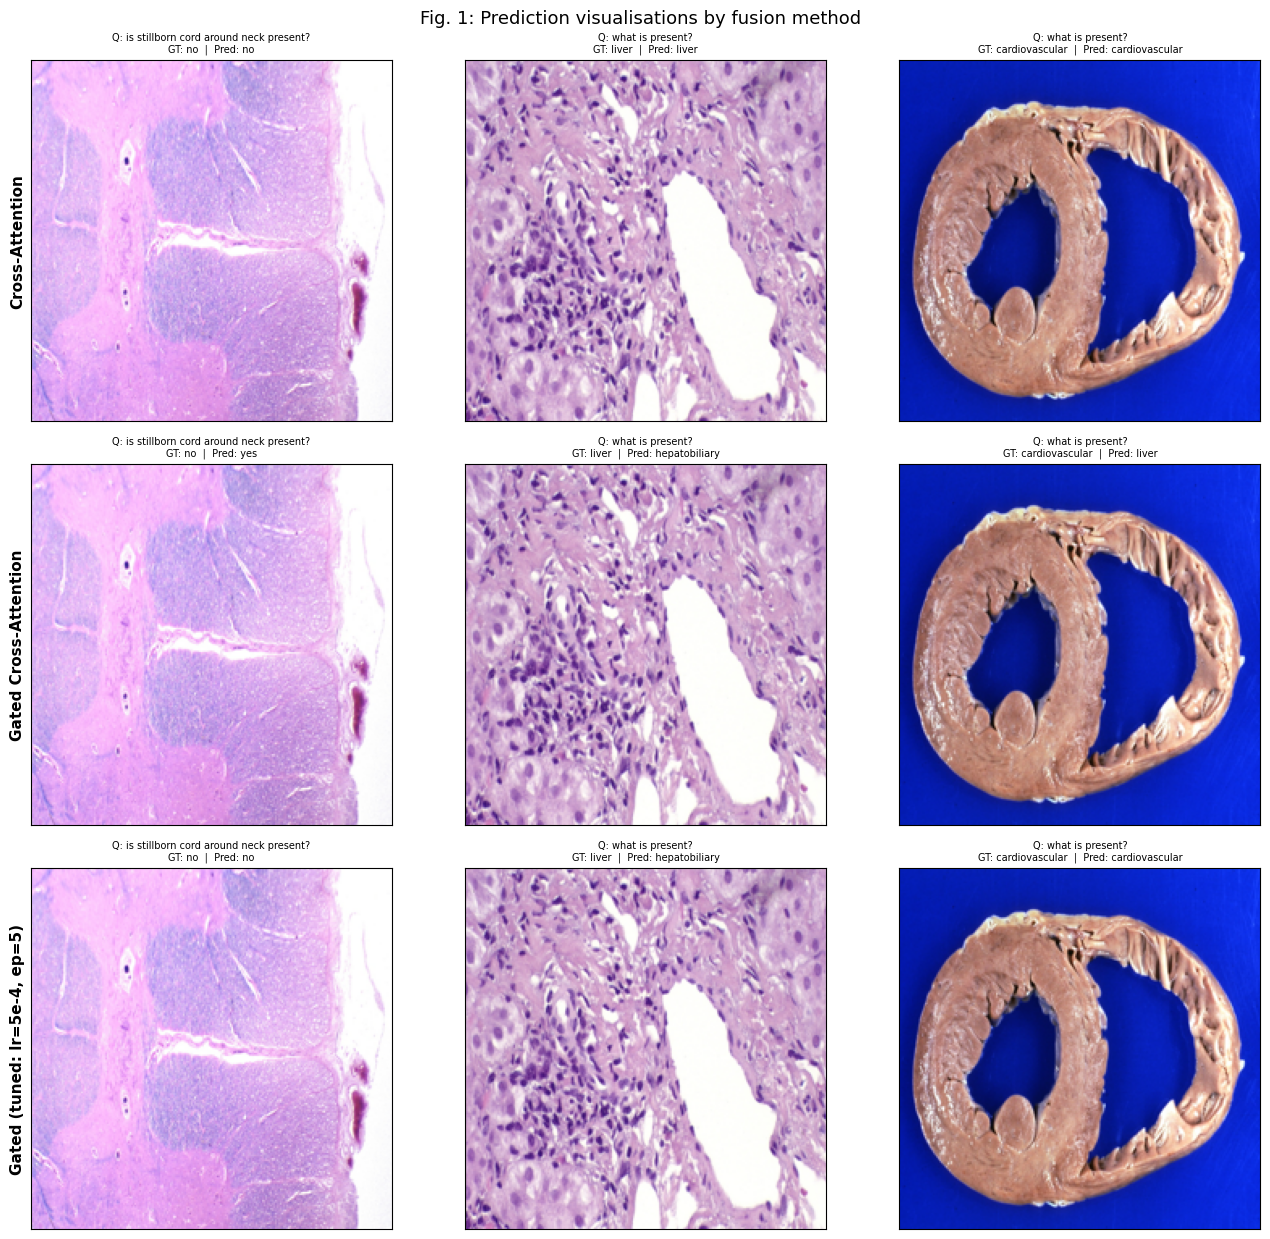

In [16]:
# === Fig. 1: prediction visualisations, one row per method =================
n_rows = len(FIG1)
n_cols = len(PANEL_INDICES)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 4.2 * n_rows))

# Make axes indexing uniform whatever the number of rows
import numpy as np
axes = np.atleast_2d(axes)
if n_cols == 1:
    axes = axes.reshape(n_rows, 1)

for r, (name, panels) in enumerate(FIG1):
    for c, p in enumerate(panels):
        ax = axes[r, c]
        ax.imshow(p["img"])
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"Q: {p['q']}\nGT: {p['gt']}  |  Pred: {p['pred']}", fontsize=7)
        if c == 0:
            ax.set_ylabel(name, fontsize=11, fontweight='bold')

fig.suptitle("Fig. 1: Prediction visualisations by fusion method", fontsize=13)
plt.tight_layout()
plt.savefig("fig1_predictions.png", dpi=150, bbox_inches='tight')
plt.show()